# Задание 4. Предсказание года выпуска песни

Используется **только выданный поднабор** из `task4_data`: `train_x.csv`, `train_y.csv`, `test_x.csv`.
Решение самостоятельно и не зависит от ноутбуков заданий 1–3. Полный YearPredictionMSD, внешние метки и ансамбли не используются.

Цель — обучить одну полносвязную нейросеть для регрессии. Последовательность из семинарского
`notebooks/pytorch_intro.ipynb`: `Dataset`/`DataLoader` → `nn.Module` → `zero_grad()` → `backward()` → `step()`;
для оценки используются `eval()` и `inference_mode()`.

**План эксперимента.** Отделить 15% строк для однократного итогового контроля, ещё 15% — для выбора
предобработки, архитектуры и числа эпох. Сравнить константу, линейный слой и несколько нейросетей.
Для лучшей конфигурации сравнить встроенный AdamW с собственной реализацией. После оценки переобучить
одну выбранную модель на всех размеченных строках и получить 6000 предсказаний.

**Метрика.** В условиях и `dataset_info` метрика Kaggle не указана; страница соревнования требует входа.
До уточнения используем RMSE (в годах), оптимизируя MSE; обе метрики одинаково ранжируют модели на фиксированной выборке.
Также выводим MAE. Если на Kaggle используется MAE, необходимо поменять `SELECTION_METRIC` на `mae`
и выполнить ноутбук заново: выбор модели и функция потерь изменятся вместе.

In [1]:
import base64
import copy
import hashlib
import io
import math
import random
import time
import unittest
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from IPython.display import HTML, Markdown, display
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import QuantileTransformer, RobustScaler, StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
SELECTION_METRIC = "rmse"  # "rmse", "mse" или "mae"; см. пояснение выше.
assert SELECTION_METRIC in {"rmse", "mse", "mae"}
MAX_EPOCHS = 160
PATIENCE = 25
BATCH_SIZE = 256
# CPU выбран для воспроизводимого сравнения двух реализаций оптимизатора.
# Для большого запуска можно указать "cuda" или "mps", если устройство доступно.
DEVICE = torch.device("cpu")
torch.set_num_threads(2)


def seed_everything(seed=SEED):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True)


seed_everything()
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.25})
print(f"torch={torch.__version__}; numpy={np.__version__}; "
      f"pandas={pd.__version__}; sklearn={sklearn.__version__}; device={DEVICE}")

torch=2.14.1; numpy=2.4.6; pandas=3.0.3; sklearn=1.9.0; device=cpu


Matplotlib is building the font cache; this may take a moment.


## 1. Загрузка и проверка данных

В `train_x.csv` и `train_y.csv` первый безымянный столбец — индекс строки, а в `test_x.csv`
есть отдельный столбец `id`. Индекс нужен для точного соединения признаков с годом, `id` — для submission;
ни тот, ни другой не поступает в сеть. Совпадение чисел в этих двух видах идентификаторов не означает,
что объекты совпадают. Числовые имена признаков читаем как имена столбцов, а не номера строк.

In [2]:
candidates = [Path("task4_data"), Path("homeworks/task4_data")]
DATA_DIR = next((p for p in candidates if (p / "train_x.csv").is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Запустите ноутбук из корня репозитория или из homeworks.")

train_x = pd.read_csv(DATA_DIR / "train_x.csv", index_col=0)
train_y = pd.read_csv(DATA_DIR / "train_y.csv", index_col=0)
test_table = pd.read_csv(DATA_DIR / "test_x.csv")
assert train_x.index.is_unique and train_y.index.is_unique
assert set(train_x.index) == set(train_y.index), "Индексы признаков и меток не совпадают"
train_y = train_y.loc[train_x.index]
assert list(train_y.columns) == ["year"]
assert "id" in test_table and test_table["id"].is_unique
assert not test_table["id"].isna().any()

feature_columns = list(train_x.columns)
assert len(feature_columns) == 90
assert set(test_table.columns) == set(feature_columns) | {"id"}
test_ids = test_table["id"].copy()
test_x = test_table.loc[:, feature_columns].copy()
assert all(pd.api.types.is_numeric_dtype(t) for t in train_x.dtypes)
assert all(pd.api.types.is_numeric_dtype(t) for t in test_x.dtypes)
X = train_x.to_numpy(dtype=np.float64)
X_test = test_x.to_numpy(dtype=np.float64)
y = torch.tensor(train_y["year"].to_numpy(dtype=np.float32))
assert torch.isfinite(y).all() and len(y) == len(X)
assert torch.equal(y, y.round()), "Годы должны быть целыми"
assert not np.isinf(X).any() and not np.isinf(X_test).any()

print(f"Обучение: {X.shape}; тест: {X_test.shape}; целевая переменная: year")
print(f"Пропуски: train={np.isnan(X).sum()}, test={np.isnan(X_test).sum()}")
print(f"Точные дубликаты train: {train_x.duplicated().sum()}")
for name in ("train_x.csv", "train_y.csv", "test_x.csv"):
    print(name, "SHA256:", hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest())

Обучение: (14000, 90); тест: (6000, 90); целевая переменная: year
Пропуски: train=0, test=0
Точные дубликаты train: 0
train_x.csv SHA256: aab2f64a4fdb0fd6af98ed95fedc9a3d9a54506b1f607da725926f654f5bff89
train_y.csv SHA256: 1f72519091e6e08948c430a1db9b181df28095e0cc9f29694570b40daed683bf
test_x.csv SHA256: 54f91d13c6f61fd634bae76bdad109471585a4ce0b308159be16f768134b4046


## 2. Разбиение до обучения преобразований

Используем 70% / 15% / 15% для train / validation / audit. Стратификация по укрупнённым периодам
сохраняет редкие старые песни в разбиениях; по отдельным годам её выполнить нельзя, поскольку
некоторые годы представлены единственной песней. Проверяем отсутствие пересечения индексов и
точно одинаковых признаков между train и holdout. Статистики preprocessing и масштаба цели
оцениваются **только по train**. Validation используется для выбора, audit открывается после фиксации решения.

В `dataset_info` приведено правило разбиения **полного** датасета. Здесь выдан другой поднабор,
поэтому переносить границу 463715 на номера строк этих CSV некорректно. Без идентификатора исполнителя
нельзя гарантировать отсутствие песен одного артиста в разных частях; локальная оценка может быть оптимистичной.

train=9800, validation=2100, audit=2100
Train: mean=1998.37, std=11.07, min=1922, max=2011


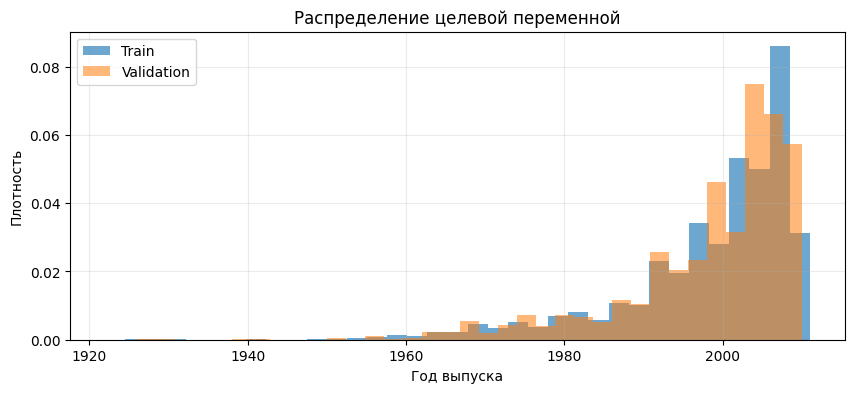

In [3]:
# NumPy/sklearn здесь применяются только к предварительному разбиению данных.
periods = np.digitize(y.tolist(), bins=[1970, 1980, 1990, 2000, 2005])
indices = np.arange(len(X))
development_idx, audit_idx = train_test_split(
    indices, test_size=0.15, random_state=SEED, stratify=periods
)
train_idx, valid_idx = train_test_split(
    development_idx, test_size=0.15 / 0.85, random_state=SEED,
    stratify=periods[development_idx]
)
assert not (set(train_idx) & set(valid_idx) or set(train_idx) & set(audit_idx)
            or set(valid_idx) & set(audit_idx))
assert len(set(train_idx) | set(valid_idx) | set(audit_idx)) == len(X)
row_hashes = pd.util.hash_pandas_object(train_x, index=False)
assert not (set(row_hashes.iloc[train_idx]) & set(row_hashes.iloc[valid_idx]))
assert not (set(row_hashes.iloc[development_idx]) & set(row_hashes.iloc[audit_idx]))
y_train, y_valid = y[train_idx], y[valid_idx]
print(f"train={len(train_idx)}, validation={len(valid_idx)}, audit={len(audit_idx)}")
print(f"Train: mean={y_train.mean():.2f}, std={y_train.std():.2f}, "
      f"min={y_train.min():.0f}, max={y_train.max():.0f}")
fig, ax = plt.subplots()
ax.hist(y_train.tolist(), bins=35, density=True, alpha=0.65, label="Train")
ax.hist(y_valid.tolist(), bins=35, density=True, alpha=0.55, label="Validation")
ax.set(xlabel="Год выпуска", ylabel="Плотность", title="Распределение целевой переменной")
ax.legend()
plt.show()

## 3. Предобработка

Сравним три преобразования: стандартное масштабирование; robust scaling + `asinh` + стандартное
масштабирование; квантильное преобразование в приближённо нормальное распределение.
`asinh` сохраняет знак и сжимает большие по модулю значения. Квантильное преобразование ограничивает
влияние выбросов, но теряет информацию о расстояниях и значениях за пределами обучающего диапазона.
Поэтому предпочтение определяется валидацией, а не предположением о превосходстве метода.
Медианы для возможных пропусков также вычисляются исключительно на обучающей части.

Цель центрируется и делится на стандартное отклонение train. Сеть предсказывает нормированный год,
а метрики всегда считаются после обратного преобразования в годы. Никакие регрессоры sklearn не используются.

In [4]:
class FeaturePreprocessor:
    def __init__(self, kind="standard"):
        if kind not in {"standard", "asinh", "quantile"}:
            raise ValueError(kind)
        self.kind = kind
        self.imputer = SimpleImputer(strategy="median", keep_empty_features=True)

    def fit(self, x):
        z = self.imputer.fit_transform(x)
        if self.kind == "asinh":
            self.robust = RobustScaler().fit(z)
            z = np.arcsinh(self.robust.transform(z))
        self.scaler = (
            QuantileTransformer(n_quantiles=min(256, len(z)), output_distribution="normal",
                                subsample=None, random_state=SEED)
            if self.kind == "quantile" else StandardScaler()
        )
        self.scaler.fit(z)
        return self

    def transform(self, x):
        z = self.imputer.transform(x)
        if self.kind == "asinh":
            z = np.arcsinh(self.robust.transform(z))
        z = self.scaler.transform(z).astype(np.float32)
        if not np.isfinite(z).all():
            raise ValueError("Нефинитные признаки после преобразования")
        return torch.from_numpy(z.copy())


class TargetScaler:
    def __init__(self, target):
        self.mean = float(target.mean())
        self.std = max(float(target.std(unbiased=False)), 1e-6)

    def encode(self, target):
        return (target - self.mean) / self.std

    def decode(self, prediction):
        return prediction * self.std + self.mean


@torch.inference_mode()
def regression_metrics(prediction, target):
    assert prediction.shape == target.shape
    error = prediction.double() - target.double()
    mse = error.square().mean().item()
    return {"rmse": math.sqrt(mse), "mse": mse, "mae": error.abs().mean().item()}


def print_metrics(label, values):
    print(f"{label}: RMSE={values['rmse']:.4f}; MSE={values['mse']:.4f}; MAE={values['mae']:.4f}")


constant = y_train.median() if SELECTION_METRIC == "mae" else y_train.mean()
constant_valid = regression_metrics(torch.full_like(y_valid, float(constant)), y_valid)
print_metrics("Константа, validation", constant_valid)

Константа, validation: RMSE=10.9058; MSE=118.9360; MAE=8.1448


## 4. Собственный AdamW

Для каждого параметра с существующим градиентом $g_t$ храним первый и второй моменты:

$$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\quad
v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2.$$

После коррекции смещения $\hat m_t=m_t/(1-\beta_1^t)$, $\hat v_t=v_t/(1-\beta_2^t)$:

$$\theta_t=(1-\eta_t\lambda)\theta_{t-1}
-\eta_t\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}.$$

Weight decay применяется отдельно от моментов градиента. `grad=None` пропускает и обновление,
и decay, и счётчик конкретного параметра; нулевой градиент, напротив, является настоящим шагом.
Bias и параметры LayerNorm будут исключены из decay. Реализация поддерживает плотные вещественные
параметры и группы параметров; AMSGrad, sparse gradients и дифференцируемый шаг здесь не нужны.

Использованы формулы из [Loshchilov & Hutter, Decoupled Weight Decay Regularization](https://arxiv.org/abs/1711.05101)
и [документация PyTorch AdamW](https://docs.pytorch.org/docs/stable/generated/torch.optim.AdamW.html).
Это реализация того же алгоритма: систематическое улучшение над встроенной реализацией не ожидается.

In [5]:
class CustomAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay)
        super().__init__(params, defaults)
        for group in self.param_groups:
            if not math.isfinite(group["lr"]) or group["lr"] < 0:
                raise ValueError("lr должен быть конечным и неотрицательным")
            if not math.isfinite(group["eps"]) or group["eps"] <= 0:
                raise ValueError("eps должен быть конечным и положительным")
            if not math.isfinite(group["weight_decay"]) or group["weight_decay"] < 0:
                raise ValueError("weight_decay должен быть конечным и неотрицательным")
            if len(group["betas"]) != 2 or not all(0 <= b < 1 for b in group["betas"]):
                raise ValueError("betas должны лежать в [0, 1)")

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            beta1, beta2 = group["betas"]
            for parameter in group["params"]:
                grad = parameter.grad
                if grad is None:
                    continue
                if grad.is_sparse or torch.is_complex(parameter):
                    raise RuntimeError("Поддерживаются только плотные вещественные градиенты")
                state = self.state[parameter]
                if not state:
                    state["step"] = 0
                    state["exp_avg"] = torch.zeros_like(parameter)
                    state["exp_avg_sq"] = torch.zeros_like(parameter)
                state["step"] += 1
                m, v = state["exp_avg"], state["exp_avg_sq"]
                m.lerp_(grad, 1 - beta1)
                v.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)
                correction1 = 1 - beta1 ** state["step"]
                correction2 = 1 - beta2 ** state["step"]
                denominator = v.sqrt().div_(math.sqrt(correction2)).add_(group["eps"])
                parameter.mul_(1 - group["lr"] * group["weight_decay"])
                parameter.addcdiv_(m, denominator, value=-group["lr"] / correction1)
        return loss

In [6]:
class TestCustomAdamW(unittest.TestCase):
    def test_reference_steps_and_parameter_groups(self):
        generator = torch.Generator().manual_seed(101)
        ours = [nn.Parameter(torch.randn(3, 4, generator=generator, dtype=torch.float64)),
                nn.Parameter(torch.randn(4, generator=generator, dtype=torch.float64))]
        reference = [nn.Parameter(p.detach().clone()) for p in ours]
        def groups(parameters):
            return [{"params": [parameters[0]], "lr": 0.003, "weight_decay": 0.1},
                    {"params": [parameters[1]], "lr": 0.002, "weight_decay": 0.0}]
        custom = CustomAdamW(groups(ours), betas=(0.8, 0.95), eps=1e-6)
        builtin = torch.optim.AdamW(groups(reference), betas=(0.8, 0.95), eps=1e-6,
                                    foreach=False, fused=False)
        for step in range(20):
            for i, (p, q) in enumerate(zip(ours, reference)):
                grad = torch.randn(p.shape, generator=generator, dtype=p.dtype)
                if step % 4 == 0 and i == 1:
                    p.grad = q.grad = None
                else:
                    p.grad = torch.zeros_like(grad) if step == 7 else grad
                    q.grad = p.grad.clone()
            custom.step()
            builtin.step()
            for p, q in zip(ours, reference):
                torch.testing.assert_close(p, q, rtol=1e-11, atol=1e-12)

    def test_none_vs_zero_gradient(self):
        p = nn.Parameter(torch.tensor([2.0], dtype=torch.float64))
        optimizer = CustomAdamW([p], lr=0.1, weight_decay=0.2)
        optimizer.step()
        self.assertEqual(p.item(), 2.0)
        self.assertNotIn(p, optimizer.state)
        p.grad = torch.zeros_like(p)
        optimizer.step()
        self.assertAlmostEqual(p.item(), 1.96)
        self.assertEqual(optimizer.state[p]["step"], 1)

    def test_restore_state(self):
        p = nn.Parameter(torch.tensor([1.0, -2.0], dtype=torch.float64))
        a = CustomAdamW([p])
        p.grad = torch.tensor([0.3, -0.1], dtype=p.dtype)
        a.step()
        q = nn.Parameter(p.detach().clone())
        b = CustomAdamW([q])
        b.load_state_dict(copy.deepcopy(a.state_dict()))
        for _ in range(5):
            p.grad = torch.tensor([-0.2, 0.4], dtype=p.dtype)
            q.grad = p.grad.clone()
            a.step()
            b.step()
        torch.testing.assert_close(p, q, rtol=0, atol=0)

    def test_invalid_settings(self):
        for kwargs in [{"lr": -1}, {"eps": 0}, {"betas": (1, 0.9)}, {"weight_decay": -1}]:
            with self.assertRaises(ValueError):
                CustomAdamW([nn.Parameter(torch.ones(1))], **kwargs)


suite = unittest.defaultTestLoader.loadTestsFromTestCase(TestCustomAdamW)
test_result = unittest.TextTestRunner(verbosity=2).run(suite)
assert test_result.wasSuccessful()

test_invalid_settings (__main__.TestCustomAdamW.test_invalid_settings) ... ok
test_none_vs_zero_gradient (__main__.TestCustomAdamW.test_none_vs_zero_gradient) ... ok
test_reference_steps_and_parameter_groups (__main__.TestCustomAdamW.test_reference_steps_and_parameter_groups) ... ok
test_restore_state (__main__.TestCustomAdamW.test_restore_state) ... ok

----------------------------------------------------------------------
Ran 4 tests in 0.023s

OK


## 5. Одна нейросеть для табличных признаков

Базовая MLP: два скрытых слоя с ReLU и dropout. Альтернатива — сеть с двумя residual-блоками:
`LayerNorm → Linear → SiLU → Dropout → Linear`, выход блока прибавляется к его входу.
Последний линейный слой блока инициализируется нулями, поэтому в начале блок близок к тождественному
преобразованию. Это **одна сеть**, а не ансамбль. Выход — одно вещественное число без округления
и без сигмоиды: условное среднее года обычно не является целым.

Используются ранняя остановка по validation, AdamW, плавное уменьшение learning rate и ограничение
нормы градиента. Сложность умеренная: выборка содержит всего 14 тысяч размеченных песен.

In [7]:
class ResidualBlock(nn.Module):
    def __init__(self, width, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(width), nn.Linear(width, width * 2), nn.SiLU(),
            nn.Dropout(dropout), nn.Linear(width * 2, width), nn.Dropout(dropout)
        )
        nn.init.zeros_(self.net[-2].weight)
        nn.init.zeros_(self.net[-2].bias)

    def forward(self, x):
        return x + self.net(x)


class YearRegressor(nn.Module):
    def __init__(self, n_features, architecture="residual", width=128, dropout=0.15):
        super().__init__()
        if architecture == "linear":
            self.net = nn.Linear(n_features, 1)
        elif architecture == "mlp":
            self.net = nn.Sequential(
                nn.Linear(n_features, width), nn.ReLU(), nn.Dropout(dropout),
                nn.Linear(width, width), nn.ReLU(), nn.Dropout(dropout), nn.Linear(width, 1)
            )
        elif architecture == "residual":
            self.net = nn.Sequential(
                nn.Linear(n_features, width), nn.SiLU(),
                ResidualBlock(width, dropout), ResidualBlock(width, dropout),
                nn.LayerNorm(width), nn.SiLU(), nn.Linear(width, 1)
            )
        else:
            raise ValueError(architecture)

    def forward(self, x):
        return self.net(x).squeeze(-1)


def build_optimizer(model, kind, lr, weight_decay):
    decay, no_decay = [], []
    for parameter in model.parameters():
        (decay if parameter.ndim >= 2 else no_decay).append(parameter)
    groups = [{"params": decay, "weight_decay": weight_decay},
              {"params": no_decay, "weight_decay": 0.0}]
    if kind == "custom":
        return CustomAdamW(groups, lr=lr)
    if kind == "builtin":
        return torch.optim.AdamW(groups, lr=lr, foreach=False, fused=False)
    raise ValueError(kind)


@torch.inference_mode()
def predict(model, features, target_scaler, batch_size=1024):
    model.eval()
    outputs = [model(batch.to(DEVICE)).cpu() for batch in features.split(batch_size)]
    return target_scaler.decode(torch.cat(outputs))


def make_loader(features, targets, seed):
    return DataLoader(TensorDataset(features, targets), batch_size=BATCH_SIZE, shuffle=True,
                      generator=torch.Generator().manual_seed(seed), num_workers=0)


def train_epoch(model, loader, optimizer):
    model.train()
    loss_fn = nn.L1Loss() if SELECTION_METRIC == "mae" else nn.MSELoss()
    total_loss, total_grad, count = 0.0, 0.0, 0
    for features, targets in loader:
        features, targets = features.to(DEVICE), targets.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        prediction = model(features)
        assert prediction.shape == targets.shape
        loss = loss_fn(prediction, targets)
        if not torch.isfinite(loss):
            raise RuntimeError("Обучение разошлось")
        loss.backward()
        grad_norm = nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0,
                                           error_if_nonfinite=True)
        optimizer.step()
        total_loss += loss.item() * len(features)
        total_grad += float(grad_norm) * len(features)
        count += len(features)
    return total_loss / count, total_grad / count


def learning_rate(config, epoch):
    # Та же функция используется при final refit, без изменения горизонта.
    phase = (epoch - 1) / max(1, MAX_EPOCHS - 1)
    return config["lr"] * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * phase)))


def fit_experiment(config, optimizer_kind="builtin", seed=SEED):
    seed_everything(seed)
    preprocess = FeaturePreprocessor(config["preprocessing"]).fit(X[train_idx])
    xt, xv = preprocess.transform(X[train_idx]), preprocess.transform(X[valid_idx])
    target_scaler = TargetScaler(y_train)
    loader = make_loader(xt, target_scaler.encode(y_train), seed)
    model = YearRegressor(xt.shape[1], config["architecture"], config["width"],
                          config["dropout"]).to(DEVICE)
    optimizer = build_optimizer(model, optimizer_kind, config["lr"], config["weight_decay"])
    best_score, best_epoch, best_state, stale = math.inf, 0, None, 0
    history = []
    started = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        lr = learning_rate(config, epoch)
        for group in optimizer.param_groups:
            group["lr"] = lr
        loss, grad_norm = train_epoch(model, loader, optimizer)
        train_metrics = regression_metrics(predict(model, xt, target_scaler), y_train)
        valid_metrics = regression_metrics(predict(model, xv, target_scaler), y_valid)
        score = valid_metrics[SELECTION_METRIC]
        history.append({"epoch": epoch, "loss": loss, "grad_norm": grad_norm, "lr": lr,
                        **{f"train_{k}": v for k, v in train_metrics.items()},
                        **{f"valid_{k}": v for k, v in valid_metrics.items()}})
        if score < best_score:
            best_score, best_epoch, stale = score, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
        if epoch == 1 or epoch % 20 == 0:
            print(f"{config['name']} / {optimizer_kind}: epoch={epoch:3d}, "
                  f"train RMSE={train_metrics['rmse']:.4f}, valid RMSE={valid_metrics['rmse']:.4f}",
                  flush=True)
        if stale >= PATIENCE:
            break
    assert best_state is not None
    model.load_state_dict(best_state)
    predictions = predict(model, xv, target_scaler)
    result = dict(config=dict(config), optimizer=optimizer_kind, model=model.cpu(),
                  preprocessing=preprocess, target_scaler=target_scaler, history=history,
                  best_epoch=best_epoch, metrics=regression_metrics(predictions, y_valid),
                  valid_prediction=predictions, seconds=time.perf_counter() - started)
    print_metrics(f"Лучший checkpoint ({best_epoch} эпоха)", result["metrics"])
    return result

In [8]:
# Проверки касаются вычислений и утечки статистик, а не качества на выдуманной выборке.
for architecture in ("linear", "mlp", "residual"):
    seed_everything()
    model_check = YearRegressor(90, architecture, width=16)
    x_check = torch.randn(7, 90)
    y_check = torch.randn(7)
    loss_check = (model_check(x_check) - y_check).square().mean()
    loss_check.backward()
    assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in model_check.parameters())
    model_check.eval()
    assert model_check(x_check[:1]).shape == (1,)
    torch.testing.assert_close(model_check(x_check), model_check(x_check), rtol=0, atol=0)

# Изменение validation не должно менять статистики или представление train.
for kind in ("standard", "asinh", "quantile"):
    pp = FeaturePreprocessor(kind).fit(X[train_idx[:100]])
    before = pp.transform(X[train_idx[:100]])
    _ = pp.transform(X[valid_idx[:20]] * 1e4)
    torch.testing.assert_close(before, pp.transform(X[train_idx[:100]]), rtol=0, atol=0)
print("Проверки размеров, градиентов, eval() и изоляции предобработки пройдены.")

Проверки размеров, градиентов, eval() и изоляции предобработки пройдены.


## 6. Выбор конфигурации по validation

Сначала оцениваем линейный слой как обучаемую базовую модель. Затем сравниваем MLP и residual-сеть
при одинаковом standard scaling и три вида предобработки для одной residual-архитектуры.
Для всех нелинейных кандидатов одинаковы seed, размеры батчей, скорость обучения, decay и dropout.
Отбор производится по validation; audit и test не участвуют ни в ранней остановке, ни в подборе.

In [9]:
common = dict(width=128, dropout=0.15, lr=1e-3, weight_decay=1e-2)
configs = [
    dict(common, name="Linear + standard", architecture="linear", preprocessing="standard", lr=3e-3),
    dict(common, name="MLP + standard", architecture="mlp", preprocessing="standard"),
    dict(common, name="Residual + standard", architecture="residual", preprocessing="standard"),
    dict(common, name="Residual + asinh", architecture="residual", preprocessing="asinh"),
    dict(common, name="Residual + quantile", architecture="residual", preprocessing="quantile"),
]
experiments = []
for config in configs:
    experiments.append(fit_experiment(config))

print("\nРезультаты на validation (checkpoint с минимальной выбранной метрикой):")
for run in sorted(experiments, key=lambda r: r["metrics"][SELECTION_METRIC]):
    print_metrics(f"{run['config']['name']}; epoch={run['best_epoch']}; {run['seconds']:.1f} s", run["metrics"])
# Linear — базовый ориентир; итоговая модель выбирается среди нелинейных нейросетей.
neural_runs = [r for r in experiments if r["config"]["architecture"] != "linear"]
best_builtin = min(neural_runs, key=lambda r: r["metrics"][SELECTION_METRIC])
print("Выбрана конфигурация:", best_builtin["config"])

Linear + standard / builtin: epoch=  1, train RMSE=10.1795, valid RMSE=10.1995
Linear + standard / builtin: epoch= 20, train RMSE=9.5799, valid RMSE=9.6594
Linear + standard / builtin: epoch= 40, train RMSE=9.5831, valid RMSE=9.6468
Linear + standard / builtin: epoch= 60, train RMSE=9.5745, valid RMSE=9.6544
Linear + standard / builtin: epoch= 80, train RMSE=9.5753, valid RMSE=9.6488
Лучший checkpoint (71 эпоха): RMSE=9.6313; MSE=92.7624; MAE=6.8572
MLP + standard / builtin: epoch=  1, train RMSE=9.8613, valid RMSE=10.0089
MLP + standard / builtin: epoch= 20, train RMSE=6.4103, valid RMSE=9.2713
MLP + standard / builtin: epoch= 40, train RMSE=5.1040, valid RMSE=9.3123
Лучший checkpoint (18 эпоха): RMSE=9.2075; MSE=84.7777; MAE=6.3805
Residual + standard / builtin: epoch=  1, train RMSE=9.0943, valid RMSE=9.4623
Residual + standard / builtin: epoch= 20, train RMSE=4.7133, valid RMSE=10.0868
Лучший checkpoint (4 эпоха): RMSE=9.1591; MSE=83.8891; MAE=6.2957
Residual + asinh / builtin: epo

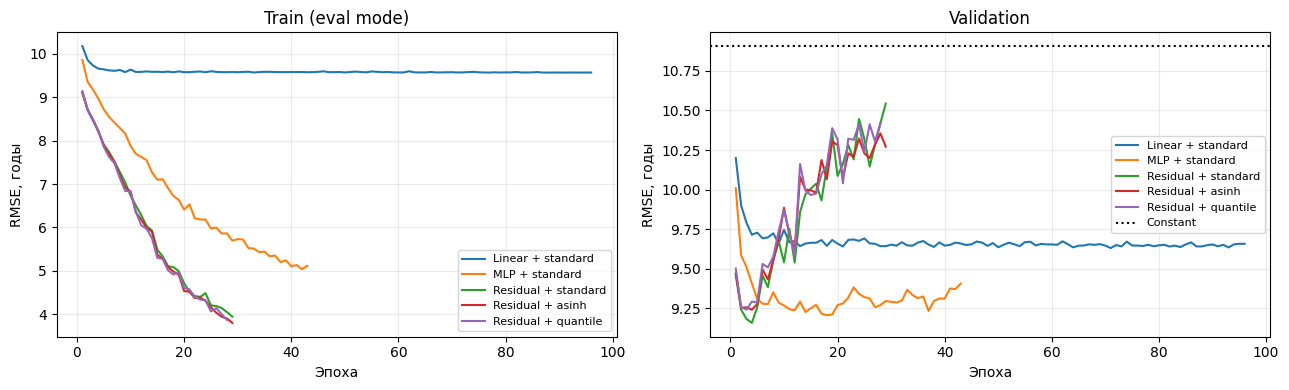

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for run in experiments:
    h = run["history"]
    epochs = [v["epoch"] for v in h]
    axes[0].plot(epochs, [v["train_rmse"] for v in h], label=run["config"]["name"])
    axes[1].plot(epochs, [v["valid_rmse"] for v in h], label=run["config"]["name"])
axes[1].axhline(constant_valid["rmse"], color="black", linestyle=":", label="Constant")
for ax, title in zip(axes, ("Train (eval mode)", "Validation")):
    ax.set(xlabel="Эпоха", ylabel="RMSE, годы", title=title)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 7. Сравнение с собственным оптимизатором

Повторяем **лучшую конфигурацию**, меняя только реализацию AdamW. Сбрасываются RNG, веса,
порядок батчей и dropout; параметры optimizer и расписание learning rate совпадают.
Результаты не усредняются. Если метрики совпадают с точностью до `1e-4` в единицах выбранной метрики,
для финального обучения используем собственную реализацию, иначе — реализацию с меньшей ошибкой.
Один seed позволяет проверить практическую эквивалентность, но не доказывает превосходство алгоритма.

Residual + standard / custom: epoch=  1, train RMSE=9.0943, valid RMSE=9.4623
Residual + standard / custom: epoch= 20, train RMSE=4.7133, valid RMSE=10.0868
Лучший checkpoint (4 эпоха): RMSE=9.1591; MSE=83.8891; MAE=6.2957
Встроенный AdamW: RMSE=9.1591; MSE=83.8891; MAE=6.2957
Собственный AdamW: RMSE=9.1591; MSE=83.8891; MAE=6.2957
Разность rmse (custom - builtin): +0.00000000
Максимальная разность предсказаний: 0.00000000 года
Время: builtin=2.9 s, custom=3.0 s
Время одного запуска зависит от нагрузки машины; это не строгий benchmark.
Фиксируем до audit: Residual + standard, custom, 4 эпох


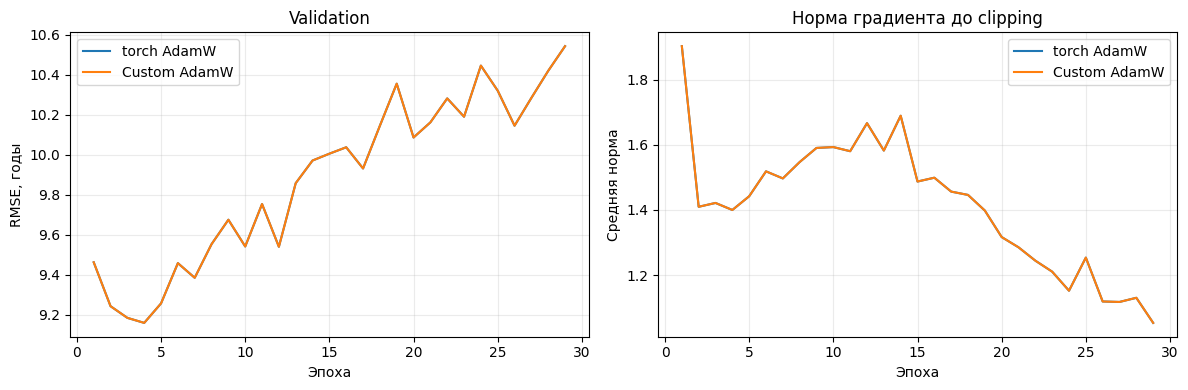

In [11]:
custom_run = fit_experiment(best_builtin["config"], optimizer_kind="custom")
print_metrics("Встроенный AdamW", best_builtin["metrics"])
print_metrics("Собственный AdamW", custom_run["metrics"])
delta = custom_run["metrics"][SELECTION_METRIC] - best_builtin["metrics"][SELECTION_METRIC]
max_prediction_delta = (custom_run["valid_prediction"] - best_builtin["valid_prediction"]).abs().max().item()
print(f"Разность {SELECTION_METRIC} (custom - builtin): {delta:+.8f}")
print(f"Максимальная разность предсказаний: {max_prediction_delta:.8f} года")
print(f"Время: builtin={best_builtin['seconds']:.1f} s, custom={custom_run['seconds']:.1f} s")
print("Время одного запуска зависит от нагрузки машины; это не строгий benchmark.")
selected = custom_run if delta <= 1e-4 else best_builtin
print(f"Фиксируем до audit: {selected['config']['name']}, {selected['optimizer']}, "
      f"{selected['best_epoch']} эпох")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for run, label in [(best_builtin, "torch AdamW"), (custom_run, "Custom AdamW")]:
    h = run["history"]
    axes[0].plot([v["epoch"] for v in h], [v["valid_rmse"] for v in h], label=label)
    axes[1].plot([v["epoch"] for v in h], [v["grad_norm"] for v in h], label=label)
axes[0].set(xlabel="Эпоха", ylabel="RMSE, годы", title="Validation")
axes[1].set(xlabel="Эпоха", ylabel="Средняя норма", title="Норма градиента до clipping")
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()

## 8. Однократная оценка на audit

Ниже впервые используются целевые значения audit для оценки модели. После этой ячейки конфигурацию
не меняем. Сравнение с константой и линейной моделью показывает, что даёт нелинейная сеть.
95%-интервал ошибки получаем bootstrap по песням при фиксированной модели; он не учитывает случайность
обучения и возможную зависимость песен одного исполнителя. Это локальная оценка, а не score Kaggle.

Audit / Константа: RMSE=11.1045; MSE=123.3106; MAE=8.2404
Audit / Линейная модель: RMSE=9.7410; MSE=94.8878; MAE=6.8911
Audit / Выбранная нейросеть: RMSE=9.3322; MSE=87.0897; MAE=6.4261
95% bootstrap-интервал rmse: [8.8413, 9.7913]


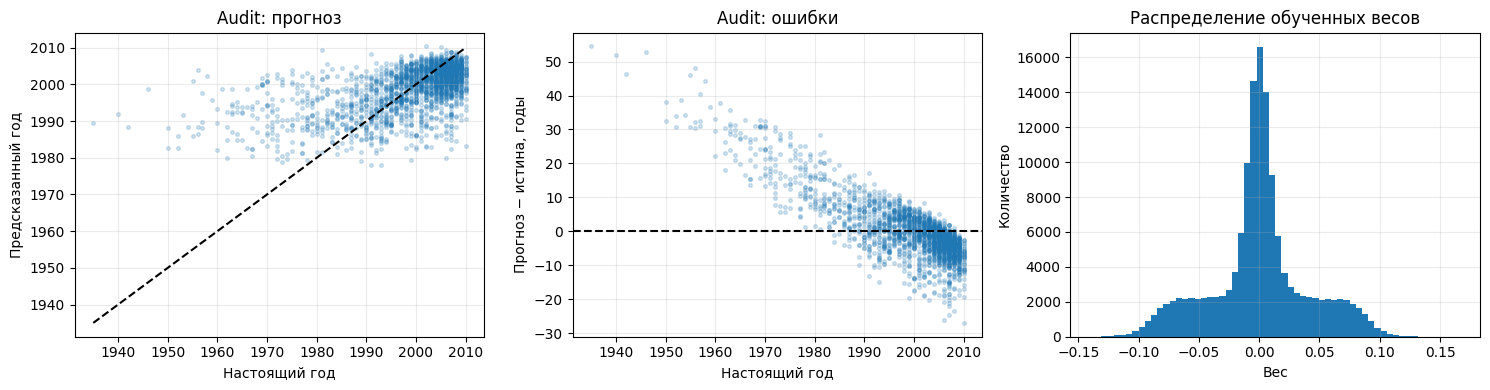

In [12]:
y_audit = y[audit_idx]
audit_features = selected["preprocessing"].transform(X[audit_idx])
audit_prediction = predict(selected["model"].to(DEVICE), audit_features, selected["target_scaler"])
audit_metrics = regression_metrics(audit_prediction, y_audit)
constant_audit = regression_metrics(torch.full_like(y_audit, float(constant)), y_audit)
linear_run = experiments[0]
linear_prediction = predict(linear_run["model"].to(DEVICE),
                            linear_run["preprocessing"].transform(X[audit_idx]),
                            linear_run["target_scaler"])
linear_audit = regression_metrics(linear_prediction, y_audit)
for name, values in [("Константа", constant_audit), ("Линейная модель", linear_audit),
                     ("Выбранная нейросеть", audit_metrics)]:
    print_metrics(f"Audit / {name}", values)

residual = audit_prediction.double() - y_audit.double()
bootstrap_generator = torch.Generator().manual_seed(2026)
bootstrap_values = []
for _ in range(1000):
    sample = torch.randint(len(residual), (len(residual),), generator=bootstrap_generator)
    errors = residual[sample]
    value = (errors.abs().mean() if SELECTION_METRIC == "mae" else errors.square().mean())
    if SELECTION_METRIC == "rmse":
        value = value.sqrt()
    bootstrap_values.append(value)
interval = torch.quantile(torch.stack(bootstrap_values), torch.tensor([0.025, 0.975], dtype=torch.float64))
print(f"95% bootstrap-интервал {SELECTION_METRIC}: [{interval[0]:.4f}, {interval[1]:.4f}]")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(y_audit.tolist(), audit_prediction.tolist(), s=7, alpha=0.2)
lo, hi = float(y_audit.min()), float(y_audit.max())
axes[0].plot([lo, hi], [lo, hi], "k--")
axes[0].set(xlabel="Настоящий год", ylabel="Предсказанный год", title="Audit: прогноз")
axes[1].scatter(y_audit.tolist(), residual.tolist(), s=7, alpha=0.2)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(xlabel="Настоящий год", ylabel="Прогноз − истина, годы", title="Audit: ошибки")
weights = torch.cat([p.detach().cpu().flatten() for p in selected["model"].parameters() if p.ndim >= 2])
axes[2].hist(weights.tolist(), bins=60)
axes[2].set(xlabel="Вес", ylabel="Количество", title="Распределение обученных весов")
fig.tight_layout()
plt.show()

## 9. Финальное обучение и submission

Теперь выбор зафиксирован. Заново обучаем предобработку и **одну** сеть на всех 14 000 размеченных
строках. Число эпох берём из validation; расписание learning rate имеет тот же горизонт, что при подборе.
Audit при этом становится частью финального обучения: его прежняя оценка относится к модели из раздела 8,
а не к переобученной сети. Тест используется только для `transform` и предсказаний.

`sample_submission.csv` не предоставлен. Используем схему `id,year`, согласованную с названиями
`id` в test и `year` в train_y; перед отправкой её необходимо сверить с Kaggle. Сохраняем исходный
порядок test, не округляем и не обрезаем предсказания. CSV будет встроен в вывод ноутбука ссылкой для
скачивания: дополнительных файлов в репозитории этот запуск не создаёт и ничего на Kaggle не отправляет.

In [13]:
seed_everything()
final_preprocessing = FeaturePreprocessor(selected["config"]["preprocessing"]).fit(X)
full_features = final_preprocessing.transform(X)
final_target_scaler = TargetScaler(y)
final_loader = make_loader(full_features, final_target_scaler.encode(y), SEED)
final_model = YearRegressor(len(feature_columns), selected["config"]["architecture"],
                            selected["config"]["width"], selected["config"]["dropout"]).to(DEVICE)
final_optimizer = build_optimizer(final_model, selected["optimizer"], selected["config"]["lr"],
                                  selected["config"]["weight_decay"])
for epoch in range(1, selected["best_epoch"] + 1):
    for group in final_optimizer.param_groups:
        group["lr"] = learning_rate(selected["config"], epoch)
    final_loss, final_grad = train_epoch(final_model, final_loader, final_optimizer)
    if epoch == 1 or epoch % 20 == 0 or epoch == selected["best_epoch"]:
        print(f"Final refit: epoch={epoch}, normalized loss={final_loss:.5f}", flush=True)

predictions = predict(final_model, final_preprocessing.transform(X_test), final_target_scaler)
assert predictions.shape == (len(test_table),) and torch.isfinite(predictions).all()
# pandas и NumPy используются здесь только для сборки CSV.
submission = pd.DataFrame({"id": test_ids.to_numpy(), "year": predictions.numpy()})
assert list(submission.columns) == ["id", "year"]
assert len(submission) == len(test_table) and submission["id"].is_unique
assert submission["id"].equals(test_ids.reset_index(drop=True))
csv_text = submission.to_csv(index=False, float_format="%.6f")
roundtrip = pd.read_csv(io.StringIO(csv_text))
assert roundtrip["id"].equals(submission["id"])
torch.testing.assert_close(torch.tensor(roundtrip["year"].to_numpy()), predictions.double(),
                           rtol=0, atol=1e-6)
print(f"Submission: {len(submission)} строк, столбцы {list(submission.columns)}")
print(f"Диапазон прогнозов: {predictions.min():.2f} — {predictions.max():.2f}")
display(submission.head())
csv_base64 = base64.b64encode(csv_text.encode("utf-8")).decode("ascii")
display(HTML(f'<a download="task4_submission.csv" href="data:text/csv;base64,{csv_base64}">'
             'Скачать task4_submission.csv</a>'))
# При необходимости выгрузки в отдельный файл вручную:
# submission.to_csv("task4_submission.csv", index=False)

Final refit: epoch=1, normalized loss=0.78853
Final refit: epoch=4, normalized loss=0.61436
Submission: 6000 строк, столбцы ['id', 'year']
Диапазон прогнозов: 1975.58 — 2010.53


,id,year
0,3416,1999.819580
1,18991,2003.499023
2,11105,2000.195801
3,18902,2003.263550
4,18958,2004.534668


In [14]:
relative_improvement = 100 * (1 - audit_metrics["rmse"] / constant_audit["rmse"])
optimizer_conclusion = (
    "Практической разницы качества между реализациями не обнаружено при выбранной точности."
    if abs(delta) <= 1e-4 else
    "Обнаружено численное различие; один запуск не позволяет утверждать превосходство реализации."
)
report = f"""
### Выводы по выполненному запуску

- По validation выбрана **{selected['config']['name']}**; оптимизатор **{selected['optimizer']}**,
  число эпох для финального обучения — **{selected['best_epoch']}**.
- Validation: RMSE **{selected['metrics']['rmse']:.4f}**, MAE **{selected['metrics']['mae']:.4f}** года.
- Audit (2100 песен, до refit): RMSE **{audit_metrics['rmse']:.4f}**, MAE **{audit_metrics['mae']:.4f}** года.
  Константа: RMSE **{constant_audit['rmse']:.4f}**; линейный слой: **{linear_audit['rmse']:.4f}**.
  Изменение RMSE относительно константы: **{relative_improvement:+.2f}% улучшения**.
- Custom − builtin по {SELECTION_METRIC}: **{delta:+.8f}**. {optimizer_conclusion}
- Получены **{len(submission)}** предсказаний одной финальной сети. Метрика скрытого теста неизвестна:
  submission не отправлялся. Место в рейтинге и бонус за топ участников по локальной оценке определить нельзя.

Подбор ограничен перечисленными конфигурациями. Интервал bootstrap описывает неопределённость
локальной оценки при фиксированной модели; повторные seed и разбиение по артистам потребовали бы отдельного эксперимента.
"""
display(Markdown(report))


### Выводы по выполненному запуску

- По validation выбрана **Residual + standard**; оптимизатор **custom**,
  число эпох для финального обучения — **4**.
- Validation: RMSE **9.1591**, MAE **6.2957** года.
- Audit (2100 песен, до refit): RMSE **9.3322**, MAE **6.4261** года.
  Константа: RMSE **11.1045**; линейный слой: **9.7410**.
  Изменение RMSE относительно константы: **+15.96% улучшения**.
- Custom − builtin по rmse: **+0.00000000**. Практической разницы качества между реализациями не обнаружено при выбранной точности.
- Получены **6000** предсказаний одной финальной сети. Метрика скрытого теста неизвестна:
  submission не отправлялся. Место в рейтинге и бонус за топ участников по локальной оценке определить нельзя.

Подбор ограничен перечисленными конфигурациями. Интервал bootstrap описывает неопределённость
локальной оценки при фиксированной модели; повторные seed и разбиение по артистам потребовали бы отдельного эксперимента.


## Интерпретация результатов

При одинаковой residual-архитектуре standard scaling дал validation RMSE **9.1591**, `asinh` —
**9.2421**, quantile transform — **9.2427**. Усложнение предобработки в этом запуске не помогло.
Простая MLP получила **9.2075**: преимущество residual-сети невелико и без нескольких seed не является
доказательством общего превосходства архитектуры.

На графиках train RMSE продолжает снижаться, тогда как validation RMSE residual-сетей после первых
эпох растёт. Это выраженное переобучение. Поэтому для прогноза восстановлены веса **4-й эпохи**, а не
последней выполненной эпохи. Увеличение числа эпох само по себе здесь ухудшает обобщение.

На audit RMSE сети составляет **9.3322** года (bootstrap-интервал **[8.8413, 9.7913]**),
MAE — **6.4261** года. RMSE на **15.96%** ниже ошибки константы и примерно на **4.20%** ниже ошибки
линейной модели. Эти значения относятся к локальному разбиению, не к скрытому тесту Kaggle.

На диаграмме ошибок старые песни чаще получают завышенный год. Это согласуется с тем, что они редки,
а основная масса обучающих примеров относится к поздним годам; при MSE сеть тяготеет к условному среднему.
Одного графика недостаточно, чтобы установить причину: признаки также могут плохо различать эпохи.
Наблюдение зафиксировано после audit и не использовалось для изменения модели.

Собственный и встроенный AdamW дали одинаковые validation-предсказания в этом воспроизводимом CPU-запуске
(максимальная разность **0**). Это ожидаемо для двух реализаций одной формулы; бонусный эксперимент
не следует интерпретировать как введение нового, более качественного метода оптимизации.


## Источники

1. `notebooks/pytorch_intro.ipynb` — локальный семинар: DataLoader, nn.Module, autograd и цикл обучения.
2. [Условие соревнования](https://www.kaggle.com/t/dace4caa40384c86a9879217eaccab42) и `homeworks/pytorch.md`.
3. [UCI: YearPredictionMSD](https://archive.ics.uci.edu/dataset/203/yearpredictionmsd) — описание
   90 признаков (12 средних и 78 ковариаций тембра) и ограничения исходного разбиения. Данные оттуда не загружались.
4. [Million Song Dataset](https://millionsongdataset.com/) — происхождение признаков; сторонние данные не использовались.
5. [Loshchilov & Hutter: Decoupled Weight Decay Regularization](https://arxiv.org/abs/1711.05101) — формула AdamW.
6. [PyTorch: AdamW](https://docs.pytorch.org/docs/stable/generated/torch.optim.AdamW.html) — семантика и эталон тестов.
7. [PyTorch: Reproducibility](https://docs.pytorch.org/docs/stable/notes/randomness.html) — фиксирование seed;
   побитовое совпадение разных устройств и версий библиотек не гарантируется.

Модель, preprocessing и сравнение реализованы в этом ноутбуке; готовые решения соревнования не использовались.